# Statistical Data Analysis

# Choosing the More Promising Plan for a Telecom Operator

## Project Description

**Goal:** Analyze two prepaid plans on a sample of mobile operator customers. Build a profile of the users: which services they need (calls, messages, internet traffic) and which plan they use. Analyze customer behavior and conclude which plan is better.

**Plan:**
- 1. Initial look at the data
- 2. Data preparation
    - 2.1 Converting the tables
    - 2.2 Calculating additional per-user metrics
    - 2.3 Removing outliers
- 3. Data analysis
    - 3.1 Call minutes
    - 3.2 Number of messages
    - 3.3 Internet traffic
    - 3.4 Revenue by plan
- 4. Hypothesis testing
    - 4.1 Average revenue of "Ultra" and "Smart" users
    - 4.2 Average revenue of users from Moscow and from other regions
    - 4.3 Alternative hypothesis tests
- 5. Overall conclusion

## Data Description

The operator offers its customers two plans. The task is to find out which one is more profitable for different customers.

- **Table `users`** (user information):
    `user_id` - unique user ID
    `first_name` - first name
    `last_name` - last name
    `age` - age (years)
    `reg_date` - plan activation date (day, month, year)
    `churn_date` - date the user stopped using the plan (if missing, the plan was still active when the data was exported)
    `city` - city of residence
    `tariff` - plan name

- **Table `calls`** (call information):
    `id` - unique call ID
    `call_date` - call date
    `duration` - call duration in minutes
    `user_id` - ID of the user who made the call

- **Table `messages`** (message information):
    `id` - unique message ID
    `message_date` - message date
    `user_id` - ID of the user who sent the message

- **Table `internet`** (internet session information):
    `id` - unique session ID
    `mb_used` - traffic used during the session (in megabytes)
    `session_date` - session date
    `user_id` - user ID

- **Table `tariffs`** (plan information):
    `tariff_name` - plan name
    `rub_monthly_fee` - monthly fee in rubles
    `minutes_included` - call minutes per month included in the fee
    `messages_included` - messages per month included in the fee
    `mb_per_month_included` - internet traffic included in the fee (in megabytes)
    `rub_per_minute` - price of a call minute beyond the plan (for example, if the plan includes 100 minutes per month, the charge starts at minute 101)
    `rub_per_message` - price of a message beyond the plan
    `rub_per_gb` - price of an extra gigabyte of traffic beyond the plan (1 gigabyte = 1024 megabytes)

## Step 1. Initial Look at the Data

Import the libraries:
- `pandas` for tables
- `numpy` for vector operations (np.ceil)
- `matplotlib`, `seaborn`, `plotly` for visualization
- `display` for printing tables
- `stats` for statistical tests and hypothesis testing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from IPython.display import display
import math
from scipy import stats as st

Load the data from the .csv files and print the first 10 rows of every table for a first look.
Also use `info()` to check the table structure: data types, number of rows and columns, missing values.

In [2]:
# read the data from the .csv files with read_csv()
users = pd.read_csv('users.csv')
calls = pd.read_csv('calls.csv')
messages = pd.read_csv('messages.csv')
internet = pd.read_csv('internet.csv')
tariffs = pd.read_csv('tariffs.csv')

In [3]:
# print the first 10 rows of the table with head()
display('users:',users.head(10))
# check the table structure with info(): data types, number of rows and columns, missing values.
users.info()

'users:'

,user_id,age,churn_date,city,first_name,last_name,reg_date,tariff
0,1000,52,NaN,Краснодар,Рафаил,Верещагин,2018-05-25,ultra
1,1001,41,NaN,Москва,Иван,Ежов,2018-11-01,smart
2,1002,59,NaN,Стерлитамак,Евгений,Абрамович,2018-06-17,smart
3,1003,23,NaN,Москва,Белла,Белякова,2018-08-17,ultra
4,1004,68,NaN,Новокузнецк,Татьяна,Авдеенко,2018-05-14,ultra
5,1005,67,NaN,Набережные Челны,Афанасий,Горлов,2018-01-25,smart
6,1006,21,NaN,Ульяновск,Леонид,Ермолаев,2018-02-26,smart
7,1007,65,NaN,Москва,Юна,Березина,2018-04-19,smart
8,1008,63,NaN,Челябинск,Рустэм,Пономарёв,2018-12-19,smart
9,1009,24,NaN,Пермь,Василиса,Блинова,2018-03-22,smart


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   age         500 non-null    int64 
 2   churn_date  38 non-null     object
 3   city        500 non-null    object
 4   first_name  500 non-null    object
 5   last_name   500 non-null    object
 6   reg_date    500 non-null    object
 7   tariff      500 non-null    object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB


- The `users` table has 500 rows and no duplicates. The data matches the description.
- The `churn_date` column has many missing values. They belong to plans that were still active at export time, so we leave them as they are. The data type must be changed to `datetime`.
- The data type of `reg_date` must be changed to `datetime`.
- To save memory, the plan names in `tariff` can be replaced with identifiers (smart=0, ultra=1) and the type changed to `int64`.

In [4]:
display('calls:', calls.head(10))
calls.info()

'calls:'

,id,call_date,duration,user_id
0,1000_0,2018-07-25,0.00,1000
1,1000_1,2018-08-17,0.00,1000
2,1000_2,2018-06-11,2.85,1000
3,1000_3,2018-09-21,13.80,1000
4,1000_4,2018-12-15,5.18,1000
5,1000_5,2018-11-02,0.00,1000
6,1000_6,2018-10-18,0.00,1000
7,1000_7,2018-08-22,18.31,1000
8,1000_8,2018-09-15,18.44,1000
9,1000_9,2018-08-15,0.00,1000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202607 entries, 0 to 202606
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         202607 non-null  object 
 1   call_date  202607 non-null  object 
 2   duration   202607 non-null  float64
 3   user_id    202607 non-null  int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 6.2+ MB


- The `calls` table has 202607 rows. There are no missing values or duplicates. The data matches the description.
- To save memory, remove all non-numeric characters from `id` (the IDs stay unique: the first 4 digits are the user ID, the rest is the call ID) and convert the column to `int64`.
- The type of `call_date` must be changed to `datetime`.
- The values in `duration` must be rounded up and converted to integers.
- Zero values in `duration` correspond to missed calls. We leave them as they are for now.

In [5]:
display('messages:', messages.head(10))
messages.info()

'messages:'

,id,message_date,user_id
0,1000_0,2018-06-27,1000
1,1000_1,2018-10-08,1000
2,1000_2,2018-08-04,1000
3,1000_3,2018-06-16,1000
4,1000_4,2018-12-05,1000
5,1000_5,2018-06-20,1000
6,1000_6,2018-11-19,1000
7,1000_7,2018-10-29,1000
8,1000_8,2018-06-25,1000
9,1000_9,2018-12-18,1000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123036 entries, 0 to 123035
Data columns (total 3 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            123036 non-null  object
 1   message_date  123036 non-null  object
 2   user_id       123036 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 2.8+ MB


- The `messages` table has 123036 rows. There are no missing values or duplicates. The data matches the description.
- To save memory, remove all non-numeric characters from `id` (the IDs stay unique: the first 4 digits are the user ID, the rest is the message ID) and convert the column to `int64`.
- The type of `message_date` must be changed to `datetime`.

In [6]:
display('internet:', internet.head(10))
internet.info()

'internet:'

,Unnamed: 0,id,mb_used,session_date,user_id
0,0,1000_0,112.95,2018-11-25,1000
1,1,1000_1,1052.81,2018-09-07,1000
2,2,1000_2,1197.26,2018-06-25,1000
3,3,1000_3,550.27,2018-08-22,1000
4,4,1000_4,302.56,2018-09-24,1000
5,5,1000_5,399.97,2018-10-02,1000
6,6,1000_6,540.08,2018-09-07,1000
7,7,1000_7,415.70,2018-07-11,1000
8,8,1000_8,505.40,2018-10-08,1000
9,9,1000_9,345.54,2018-09-03,1000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149396 entries, 0 to 149395
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Unnamed: 0    149396 non-null  int64  
 1   id            149396 non-null  object 
 2   mb_used       149396 non-null  float64
 3   session_date  149396 non-null  object 
 4   user_id       149396 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 5.7+ MB


- The `internet` table has 149396 rows. There are no missing values or duplicates. The data matches the description.
- To save memory, remove all non-numeric characters from `id` (the IDs stay unique: the first 4 digits are the user ID, the rest is the session ID) and convert the column to `int64`.
- The type of `session_date` must be changed to `datetime`.
- The `mb_used` column is rounded up and converted to integers.
- The `Unnamed: 0` column was probably created by an export error and can be dropped.

In [7]:
display('tariffs', tariffs.head(10))

'tariffs'

,messages_included,mb_per_month_included,minutes_included,rub_monthly_fee,rub_per_gb,rub_per_message,rub_per_minute,tariff_name
0,50,15360,500,550,200,3,3,smart
1,1000,30720,3000,1950,150,1,1,ultra


### Conclusions

- The data is loaded from the files successfully. No duplicates were found. The data matches the description.
- The general structure of the tables is checked. The initial preprocessing goals are defined (data types, missing values, simpler representation).
- Further analysis is needed to look for hidden errors.

## Step 2. Data Preparation

### 2.1 Converting the Tables

**1) Table `users`**

- Change the types of `reg_date` and `churn_date` to `datetime` with `to_datetime`.

In [8]:
users['reg_date'] = pd.to_datetime(users['reg_date'], format='%Y-%m-%d')
users['churn_date'] = pd.to_datetime(users['churn_date'], format='%Y-%m-%d')

- Replace the plan names in `tariff` with identifiers (smart=0, ultra=1) and change the type to integer.

In [9]:
# create a dictionary: keys are the plan names, values are their identifiers, matching the indices in the 'tariffs' table
tarif_dict = {'smart': 0, 'ultra': 1}
# replace the plan names with identifiers using map()
users['tariff'] = users['tariff'].map(tarif_dict)
# convert the type to int8 to save memory, using to_numeric() with downcast='integer'
users['tariff'] = pd.to_numeric(users['tariff'], downcast='integer') 

In [10]:
# look at the result of the conversions.
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     500 non-null    int64         
 1   age         500 non-null    int64         
 2   churn_date  38 non-null     datetime64[ns]
 3   city        500 non-null    object        
 4   first_name  500 non-null    object        
 5   last_name   500 non-null    object        
 6   reg_date    500 non-null    datetime64[ns]
 7   tariff      500 non-null    int8          
dtypes: datetime64[ns](2), int64(2), int8(1), object(3)
memory usage: 28.0+ KB


- Look at the number of users in different cities.

In [11]:
users.groupby('city')['city'].count().sort_values(ascending=False).head(10)

city
Москва              99
Санкт-Петербург     39
Новосибирск         16
Казань              14
Омск                14
Уфа                 12
Набережные Челны    11
Краснодар           11
Екатеринбург        11
Ульяновск           11
Name: city, dtype: int64

- The data is converted successfully.
- `age` and `reg_date` are distributed evenly.
- The number of users per city is consistent with the city sizes.

**2) Table `calls`**

- Change the type of `call_date` to `datetime` with `pd.to_datetime()`.

In [12]:
calls['call_date'] = pd.to_datetime(calls['call_date'], format='%Y-%m-%d')

Analyze the values in `call_date`: plot the distribution of the number of calls by month.

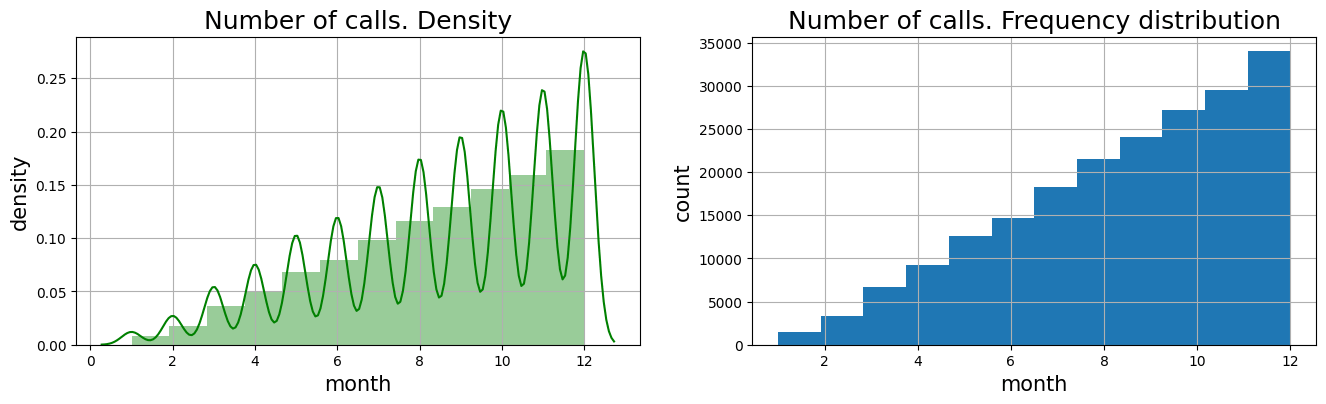

In [13]:
def show_hists(data, data_label, xlabel, num_bins, rug=False):
    """
    input: data - data for the histogram
           data_label - description of the data
           xlabel - label of the histogram bins
           num_bins - number of bins
    output: None
    description: The function draws two histograms for the selected parameter:
                - Density (with distplot() from seaborn)
                - Frequency distribution (with hist())
    """
    f, axes = plt.subplots(1, 2, figsize=(16, 4))
    axes[0].set_title(data_label + ". Density", fontsize=18)
    axes[0].set_ylabel('density', fontsize=15)
    sns.distplot(data, color="g", bins=num_bins, rug=rug, ax=axes[0])
    axes[0].set_xlabel(xlabel, fontsize=15)
    axes[0].grid()
    axes[1].set_title(data_label + ". Frequency distribution", fontsize=18)
    axes[1].set_xlabel(xlabel, fontsize=15)
    axes[1].set_ylabel('count', fontsize=15)
    data.hist(bins=num_bins, ax=axes[1])
    plt.show()
    
show_hists(calls['call_date'].dt.month, 'Number of calls', 'month', num_bins=12)

The number of calls grows linearly over the year. This may be due to the growing popularity of the operator ("Megaline"). Further analysis is needed to confirm this.

- Remove all non-numeric characters from `id` and convert the column to int64.

In [14]:
# replace all '_' characters with empty strings using replace
calls['id'] = calls['id'].replace(to_replace='_', value='', regex=True)
# convert the id type to integer with astype()
calls['id'] = calls['id'].astype('int64')

- Convert `duration`: round the values up and change the type to integer.

In [15]:
calls['duration'] = (calls['duration']
                     .apply(np.ceil)
                     .astype('int64')
                    )

Analyze the values in `duration`.

In [16]:
print('Number of missed calls:',len(calls.loc[calls['duration'] == 0]))

Number of missed calls: 39613


About 20% of the calls are missed (zero duration). We leave them as they are.
Plot the distribution of call durations for duration > 0 and look at the numeric summary with `describe()`.

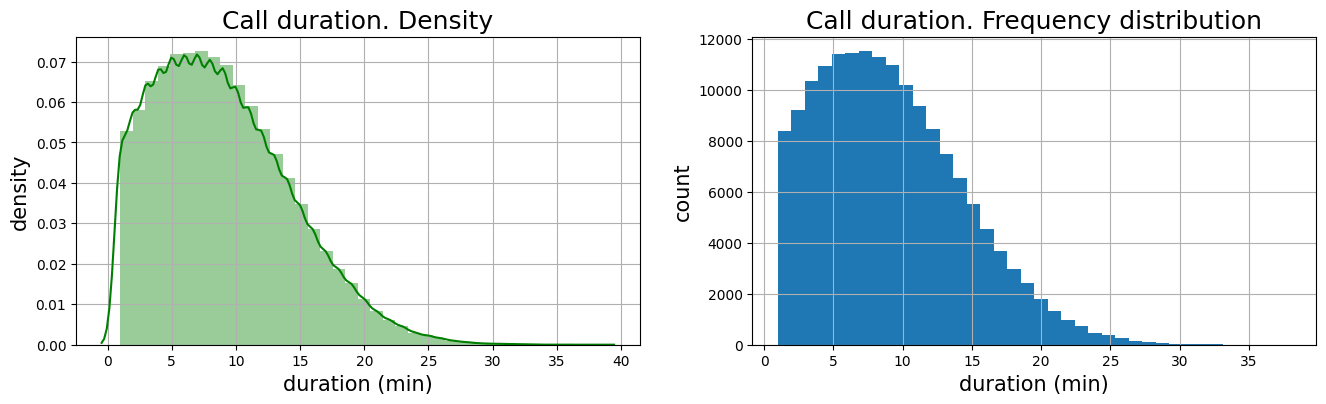

In [17]:
show_hists(calls.loc[calls['duration'] != 0, 'duration'], 'Call duration', 'duration (min)', num_bins=38)

In [18]:
calls.loc[calls['duration'] != 0, 'duration'].describe()

count    162994.000000
mean          8.897880
std           5.353761
min           1.000000
25%           5.000000
50%           8.000000
75%          12.000000
max          38.000000
Name: duration, dtype: float64

- The distribution is close to a Poisson distribution. No anomalous or implausible values were found.
- The mean (8.9) is slightly larger than the median (8): the data is slightly right-skewed, but not strongly.

In [19]:
# look at the result of the conversions
calls.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202607 entries, 0 to 202606
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   id         202607 non-null  int64         
 1   call_date  202607 non-null  datetime64[ns]
 2   duration   202607 non-null  int64         
 3   user_id    202607 non-null  int64         
dtypes: datetime64[ns](1), int64(3)
memory usage: 6.2 MB


**3) Table `messages`**

- Change the type of `message_date` to `datetime` with `pd.to_datetime()`.

In [20]:
messages['message_date'] = pd.to_datetime(messages['message_date'], format='%Y-%m-%d')

Analyze the values in `message_date`: plot the distribution of the number of messages by month.

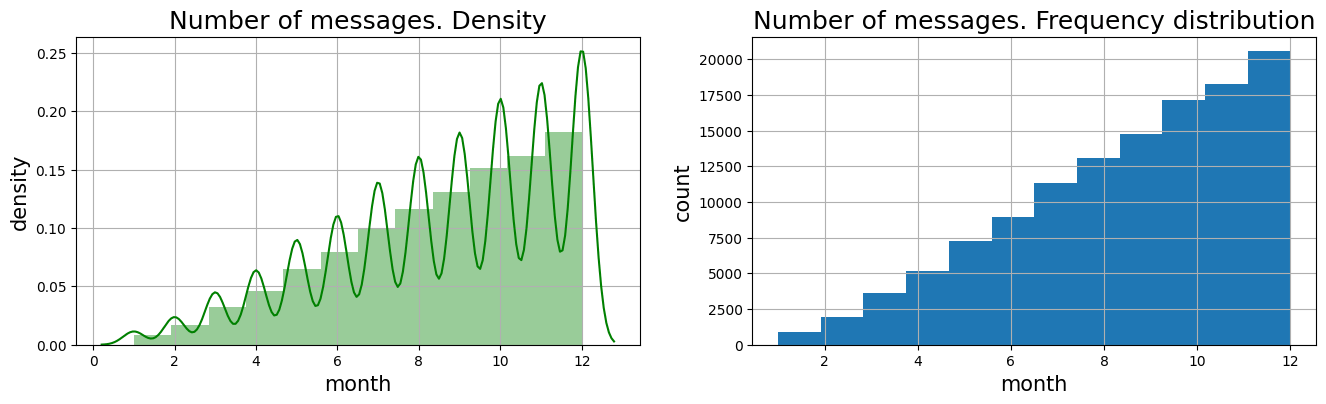

In [21]:
show_hists(messages['message_date'].dt.month, 'Number of messages', 'month', num_bins=12)

The number of messages also grows linearly over the year, perhaps because of the growing popularity of the operator. This matches the `call_date` observation in the `calls` table and is probably a feature of the data.

- Remove all non-numeric characters from `id` and convert the column to int64.

In [22]:
# replace all '_' characters with empty strings using replace
messages['id'] = messages['id'].replace(to_replace='_', value='', regex=True)
# convert the id type to integer with astype()
messages['id'] = messages['id'].astype('int64')

In [23]:
# look at the result of the conversions
messages.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123036 entries, 0 to 123035
Data columns (total 3 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            123036 non-null  int64         
 1   message_date  123036 non-null  datetime64[ns]
 2   user_id       123036 non-null  int64         
dtypes: datetime64[ns](1), int64(2)
memory usage: 2.8 MB


**4) Table `internet`**

- Drop the `Unnamed: 0` column.

In [24]:
internet = internet.drop('Unnamed: 0', 1)

- Change the type of `session_date` to `datetime` with `pd.to_datetime()`.

In [25]:
internet['session_date'] = pd.to_datetime(internet['session_date'], format='%Y-%m-%d')

Analyze the values in `session_date`: plot the distribution of the number of internet sessions by month.

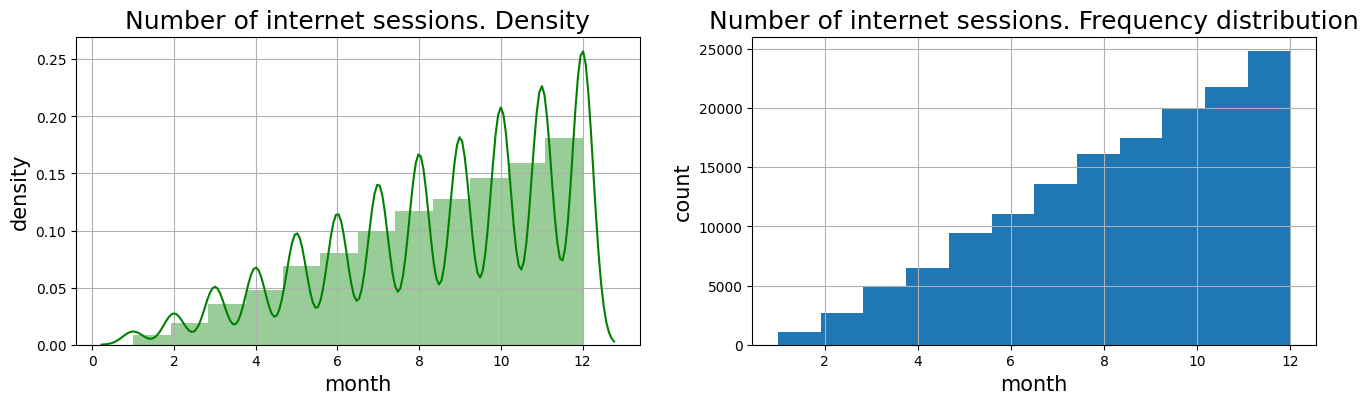

In [26]:
show_hists(internet['session_date'].dt.month, 'Number of internet sessions', 'month', num_bins=12)

The number of internet sessions also grows linearly over the year, perhaps because of the growing popularity of the operator. This matches the `call_date` and `message_date` observations in the `calls` and `messages` tables and is probably a feature of the data.

- Convert `mb_used`: round the values up and change the type to integer.

In [27]:
internet['mb_used'] = (internet['mb_used']
                       .apply(np.ceil)
                       .astype('int64')
                      )

Analyze the values in `mb_used`.

In [28]:
print('Number of sessions with zero traffic:',len(internet.loc[internet['mb_used'] == 0]))

Number of sessions with zero traffic: 19598


About 13% of the sessions have zero traffic. This may be due to a missing internet connection or a session cancelled before any data was transferred. We leave the data as it is.
Plot the distribution of traffic per session for `mb_used` > 0 and look at the numeric summary with `describe()`.

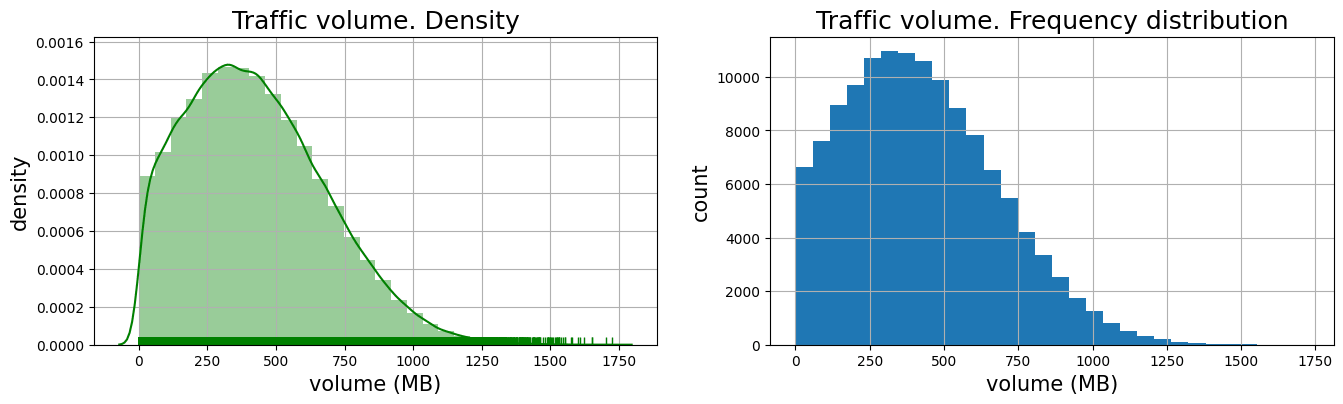

In [29]:
show_hists(internet.loc[internet['mb_used'] !=0, 'mb_used'], 'Traffic volume', 'volume (MB)', num_bins=30, rug=True)

In [30]:
internet.loc[internet['mb_used'] !=0, 'mb_used'].describe()

count    129798.000000
mean        426.581758
std         255.596114
min           1.000000
25%         228.000000
50%         401.000000
75%         593.000000
max        1725.000000
Name: mb_used, dtype: float64

- The distribution is close to a Poisson distribution. No anomalous or implausible values were found.
- The mean (426.6) is slightly larger than the median (401): the data is slightly right-skewed, but not strongly.

- Remove all non-numeric characters from `id` and convert the column to int64.

In [31]:
# replace all '_' characters with empty strings using replace
internet['id'] = internet['id'].replace(to_replace='_', value='', regex=True)
# convert the id type to integer with astype()
internet['id'] = internet['id'].astype('int64')

In [32]:
# look at the result of the conversions
internet.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149396 entries, 0 to 149395
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            149396 non-null  int64         
 1   mb_used       149396 non-null  int64         
 2   session_date  149396 non-null  datetime64[ns]
 3   user_id       149396 non-null  int64         
dtypes: datetime64[ns](1), int64(3)
memory usage: 4.6 MB


### 2.2 Calculating Additional Per-User Metrics

**1) Number of calls and minutes used, by month**

In [33]:
# add a column with the month of the call to the `calls` table.
calls['call_month'] = calls['call_date'].dt.month
# create the pivot table `calls_month`: the number of calls per user by month
calls_month = (calls
               .pivot_table(index = 'user_id',        # rows: user id
                            columns = 'call_month',   # columns: month of the call
                            values = 'id',            # values: call id
                            aggfunc = 'count')        # count the number of calls
              )
display(calls_month.head(10))

call_month,1,2,3,4,5,6,7,8,9,10,11,12
user_id,,,,,,,,,,,,
1000,NaN,NaN,NaN,NaN,22.0,43.0,47.0,52.0,58.0,57.0,43.0,46.0
1001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59.0,63.0
1002,NaN,NaN,NaN,NaN,NaN,15.0,26.0,42.0,36.0,33.0,32.0,33.0
1003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,55.0,134.0,108.0,115.0,108.0
1004,NaN,NaN,NaN,NaN,9.0,31.0,22.0,19.0,26.0,29.0,19.0,21.0
1005,15.0,69.0,77.0,101.0,73.0,80.0,77.0,71.0,66.0,100.0,75.0,84.0
1006,NaN,3.0,46.0,47.0,56.0,53.0,49.0,42.0,54.0,44.0,62.0,50.0
1007,NaN,NaN,NaN,25.0,67.0,68.0,69.0,74.0,87.0,69.0,81.0,72.0
1008,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,52.0


In [34]:
# create the pivot table `minutes_month`: the number of minutes used per user by month
minutes_month = (calls
               .pivot_table(index = 'user_id',        # rows: user id
                            columns = 'call_month',   # columns: month of the call
                            values = 'duration',      # values: call duration
                            aggfunc = 'sum')          # take the sum
              )
display(minutes_month.head(10))

call_month,1,2,3,4,5,6,7,8,9,10,11,12
user_id,,,,,,,,,,,,
1000,NaN,NaN,NaN,NaN,159.0,172.0,340.0,408.0,466.0,350.0,338.0,333.0
1001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,430.0,414.0
1002,NaN,NaN,NaN,NaN,NaN,117.0,214.0,289.0,206.0,212.0,243.0,236.0
1003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,380.0,961.0,855.0,824.0,802.0
1004,NaN,NaN,NaN,NaN,35.0,171.0,135.0,137.0,117.0,145.0,117.0,130.0
1005,95.0,456.0,606.0,712.0,595.0,612.0,569.0,619.0,479.0,723.0,547.0,592.0
1006,NaN,42.0,286.0,356.0,370.0,478.0,316.0,275.0,360.0,267.0,372.0,379.0
1007,NaN,NaN,NaN,198.0,480.0,545.0,577.0,458.0,655.0,465.0,580.0,421.0
1008,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,339.0


**2) Number of messages sent, by month**

In [35]:
# add a column with the month of the message to the `messages` table.
messages['message_month'] = messages['message_date'].dt.month
# create the pivot table `messages_month`: the number of messages per user by month
messages_month = (messages
                  .pivot_table(index = 'user_id',           # rows: user id
                               columns = 'message_month',   # columns: month the message was sent
                               values = 'id',               # values: message id
                               aggfunc = 'count')           # count the number of messages
              )
display(messages_month.head(10))

message_month,1,2,3,4,5,6,7,8,9,10,11,12
user_id,,,,,,,,,,,,
1000,NaN,NaN,NaN,NaN,22.0,60.0,75.0,81.0,57.0,73.0,58.0,70.0
1002,NaN,NaN,NaN,NaN,NaN,4.0,11.0,13.0,4.0,10.0,16.0,12.0
1003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37.0,91.0,83.0,94.0,75.0
1004,NaN,NaN,NaN,NaN,95.0,134.0,181.0,151.0,146.0,165.0,158.0,162.0
1005,7.0,38.0,56.0,41.0,42.0,47.0,56.0,64.0,52.0,44.0,51.0,54.0
1007,NaN,NaN,NaN,11.0,39.0,26.0,26.0,27.0,31.0,18.0,21.0,26.0
1008,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,56.0
1009,NaN,NaN,2.0,14.0,7.0,14.0,14.0,9.0,12.0,15.0,11.0,12.0
1011,NaN,NaN,4.0,7.0,13.0,13.0,13.0,15.0,10.0,17.0,12.0,6.0


**3) Internet traffic used, by month**

In [36]:
# add a column with the month of the session to the `internet` table.
internet['session_month'] = internet['session_date'].dt.month
# create the pivot table `traffic_month`: the amount of traffic per user by month
traffic_month = (internet
                  .pivot_table(index = 'user_id',           # rows: user id
                               columns = 'session_month',   # columns: month of the internet session
                               values = 'mb_used',          # values: traffic used
                               aggfunc = 'sum')             # take the sum of the traffic
              )
display(traffic_month.head(10))

session_month,1,2,3,4,5,6,7,8,9,10,11,12
user_id,,,,,,,,,,,,
1000,NaN,NaN,NaN,NaN,2256.0,23257.0,14016.0,14070.0,14581.0,14717.0,14768.0,9827.0
1001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18452.0,14053.0
1002,NaN,NaN,NaN,NaN,NaN,10871.0,17601.0,20347.0,16712.0,13905.0,18610.0,18137.0
1003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8571.0,12479.0,14779.0,11368.0,10132.0
1004,NaN,NaN,NaN,NaN,13415.0,17619.0,22243.0,28607.0,15125.0,18494.0,15631.0,18038.0
1005,2730.0,7394.0,11117.0,9365.0,7877.0,9875.0,7703.0,7554.0,7027.0,7809.0,12682.0,8680.0
1006,NaN,1395.0,17309.0,13954.0,12984.0,12388.0,20000.0,19327.0,15543.0,19722.0,13275.0,18498.0
1007,NaN,NaN,NaN,8031.0,17708.0,13674.0,15680.0,20723.0,12630.0,14444.0,16390.0,12512.0
1008,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13236.0


**4) Monthly revenue from each user**

The monthly revenue is calculated as follows:
- subtract the included allowance from the total number of call minutes, messages and internet traffic;
- multiply the remainder by the price from the plan;
- add the monthly fee of the plan.

First, collect all the data in one table, `earnings`. Each row holds the usage (call minutes, messages, internet traffic) of one customer in one month, together with the plan information (monthly fee, allowances and prices of extra services).

In [37]:
# collect the minutes used by each user per month with groupby() and agg().
# as_index=False keeps 'user_id' and 'call_month' in separate columns (not in a multi-index).
# save the result in the table 'calls_month'.
calls_month = calls.groupby(['user_id', 'call_month'], as_index=False)['duration'].agg('sum')
# rename the columns to simplify the later table joins
calls_month.columns = ['user_id', 'month', 'call_duration']

# collect the number of messages of each user per month with groupby() and agg().
# save the result in the table 'messages_month'.
messages_month = messages.groupby(['user_id', 'message_month'])['id'].agg('count')
messages_month.columns = ['user_id', 'month', 'message_count']

# collect the internet traffic of each user per month with groupby() and agg().
# save the result in the table 'traffic_month'.
traffic_month = internet.groupby(['user_id', 'session_month'])['mb_used'].agg('sum')
traffic_month.columns = ['user_id', 'month', 'traffic']

# join the tables 'calls_month', 'messages_month' and 'traffic_month' with join() on user and month
# how = 'outer' keeps all available records.
# save the result in the table 'earnings'
earnings = (calls_month
            .join(messages_month, on = ['user_id', 'month'], how='outer')
            .join(traffic_month, on = ['user_id', 'month'], how='outer')
            # add the plan identifier 'tariff' from the 'users' table with merge()
            # how='left' attaches the plan to every existing record of the 'earnings' table
            .merge(users[['user_id', 'tariff', 'city']], how='left', on='user_id')
           )
# rename the columns for readability
earnings.columns = ['user_id', 'month', 'call_duration', 'message_count', 'traffic', 'tariff', 'city']

# add the plan information to the 'earnings' table with join()
# how='left' adds the data to every record of the 'earnings' table
earnings = earnings.join(tariffs, on = 'tariff', how='left')

display(earnings)

,user_id,month,call_duration,message_count,traffic,tariff,city,messages_included,mb_per_month_included,minutes_included,rub_monthly_fee,rub_per_gb,rub_per_message,rub_per_minute,tariff_name
0,1000,5,159.0,22.0,2256.0,1,Краснодар,1000,30720,3000,1950,150,1,1,ultra
1,1000,6,172.0,60.0,23257.0,1,Краснодар,1000,30720,3000,1950,150,1,1,ultra
2,1000,7,340.0,75.0,14016.0,1,Краснодар,1000,30720,3000,1950,150,1,1,ultra
3,1000,8,408.0,81.0,14070.0,1,Краснодар,1000,30720,3000,1950,150,1,1,ultra
4,1000,9,466.0,57.0,14581.0,1,Краснодар,1000,30720,3000,1950,150,1,1,ultra
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3209,1489,9,NaN,32.0,17232.0,0,Санкт-Петербург,50,15360,500,550,200,3,3,smart
3210,1489,10,NaN,21.0,19588.0,0,Санкт-Петербург,50,15360,500,550,200,3,3,smart
3211,1489,11,NaN,20.0,17516.0,0,Санкт-Петербург,50,15360,500,550,200,3,3,smart
3212,1489,12,NaN,35.0,17341.0,0,Санкт-Петербург,50,15360,500,550,200,3,3,smart


- Convert the monthly usage columns (`call_duration`, `message_count`, `traffic`) to integers.
First replace all missing values in these columns with **-1**, which means that the service was not used:

In [38]:
earnings.loc[earnings['call_duration'].isna(), 'call_duration'] = -1
earnings['call_duration'] = earnings['call_duration'].astype('int64')

earnings.loc[earnings['message_count'].isna(), 'message_count'] = -1
earnings['message_count'] = earnings['message_count'].astype('int64')

earnings.loc[earnings['traffic'].isna(), 'traffic'] = -1
earnings['traffic'] = earnings['traffic'].astype('int64')

To calculate the monthly revenue of each customer, create the function `find_earnings()` and apply it to every row of the `earnings` table with `apply()`. Save the results in the `earning` column.

In [39]:
def find_earnings(row):
    """
    input: row (pd.Series) - a row of the 'earnings' table
    output: earning - monthly revenue from each user
    description:
    - subtract the included allowance from the total number of call minutes, messages and internet traffic;
    - if the remainder is greater than zero, multiply it by the price beyond the plan;
    - add the monthly fee of the plan.
    """
    # add the monthly fee to the revenue
    earning = row['rub_monthly_fee']
    # add the cost of extra minutes to the revenue, if any
    if row['call_duration'] > row['minutes_included']:
        earning += (row['call_duration'] - row['minutes_included']) * row['rub_per_minute']
    # add the cost of extra messages to the revenue, if any
    if row['message_count'] > row['messages_included']:
        earning += (row['message_count'] - row['messages_included']) * row['rub_per_message']
    # add the cost of extra internet traffic to the revenue, if any
    if row['traffic'] > row['mb_per_month_included']:
        earning += math.ceil((row['traffic'] - row['mb_per_month_included']) / 1024) * row['rub_per_gb']
    return earning

# apply the function 'find_earnings' to every row of the 'earnings' table with apply() (axis=1)
earnings['earning'] = earnings.apply(find_earnings, axis=1)
display(earnings.head(10))

,user_id,month,call_duration,message_count,traffic,tariff,city,messages_included,mb_per_month_included,minutes_included,rub_monthly_fee,rub_per_gb,rub_per_message,rub_per_minute,tariff_name,earning
0,1000,5,159,22,2256,1,Краснодар,1000,30720,3000,1950,150,1,1,ultra,1950
1,1000,6,172,60,23257,1,Краснодар,1000,30720,3000,1950,150,1,1,ultra,1950
2,1000,7,340,75,14016,1,Краснодар,1000,30720,3000,1950,150,1,1,ultra,1950
3,1000,8,408,81,14070,1,Краснодар,1000,30720,3000,1950,150,1,1,ultra,1950
4,1000,9,466,57,14581,1,Краснодар,1000,30720,3000,1950,150,1,1,ultra,1950
5,1000,10,350,73,14717,1,Краснодар,1000,30720,3000,1950,150,1,1,ultra,1950
6,1000,11,338,58,14768,1,Краснодар,1000,30720,3000,1950,150,1,1,ultra,1950
7,1000,12,333,70,9827,1,Краснодар,1000,30720,3000,1950,150,1,1,ultra,1950
8,1001,11,430,-1,18452,0,Москва,50,15360,500,550,200,3,3,smart,1350
9,1001,12,414,-1,14053,0,Москва,50,15360,500,550,200,3,3,smart,550


In [40]:
# check the general information about the earnings table: data types, number of records, etc.
earnings.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 3214 entries, 0 to 3213
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   user_id                3214 non-null   int64 
 1   month                  3214 non-null   int64 
 2   call_duration          3214 non-null   int64 
 3   message_count          3214 non-null   int64 
 4   traffic                3214 non-null   int64 
 5   tariff                 3214 non-null   int8  
 6   city                   3214 non-null   object
 7   messages_included      3214 non-null   int64 
 8   mb_per_month_included  3214 non-null   int64 
 9   minutes_included       3214 non-null   int64 
 10  rub_monthly_fee        3214 non-null   int64 
 11  rub_per_gb             3214 non-null   int64 
 12  rub_per_message        3214 non-null   int64 
 13  rub_per_minute         3214 non-null   int64 
 14  tariff_name            3214 non-null   object
 15  earning              

In [41]:
# create the pivot table `earnings_pivot`: the monthly revenue of each user
earnings_pivot = (earnings
                  .pivot_table(index = 'user_id',           # rows: user id
                               columns = 'month',           # columns: months
                               values = 'earning',          # values: monthly revenue
                               aggfunc = 'first')           # take the first (and only) value
              )
display('Monthly revenue', earnings_pivot.head(10))

'Monthly revenue'

month,1,2,3,4,5,6,7,8,9,10,11,12
user_id,,,,,,,,,,,,
1000,NaN,NaN,NaN,NaN,1950.0,1950.0,1950.0,1950.0,1950.0,1950.0,1950.0,1950.0
1001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1350.0,550.0
1002,NaN,NaN,NaN,NaN,NaN,550.0,1150.0,1550.0,950.0,550.0,1350.0,1150.0
1003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1950.0,1950.0,1950.0,1950.0,1950.0
1004,NaN,NaN,NaN,NaN,1950.0,1950.0,1950.0,1950.0,1950.0,1950.0,1950.0,1950.0
1005,550.0,550.0,886.0,1186.0,835.0,886.0,775.0,949.0,556.0,1219.0,694.0,838.0
1006,NaN,550.0,950.0,550.0,550.0,550.0,1550.0,1350.0,750.0,1550.0,550.0,1350.0
1007,NaN,NaN,NaN,550.0,1150.0,685.0,981.0,1750.0,1015.0,550.0,1190.0,550.0
1008,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,568.0


### 2.3 Removing Outliers

- Before calculating statistics, remove random outliers. To find them, plot a `boxplot` for each parameter in the `earnings` table (minutes, messages and internet traffic), read the outlier boundaries off the plots and remove the outliers.
- Outliers are defined separately for the smart and ultra plans.
- The box plots are built with `violin` from `plotly.express`. All outliers are shown as dots. The plot is interactive, so each point can be inspected separately.

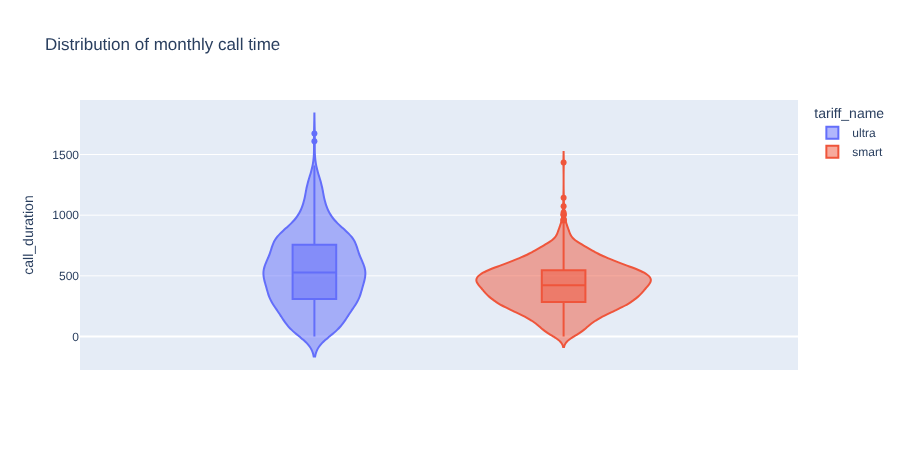

In [42]:
# plot the distribution of monthly call time.
# box=True shows a box plot inside the violin
px.violin(earnings.loc[earnings['call_duration']>=0], y="call_duration", color='tariff_name', 
          box=True, title = 'Distribution of monthly call time')

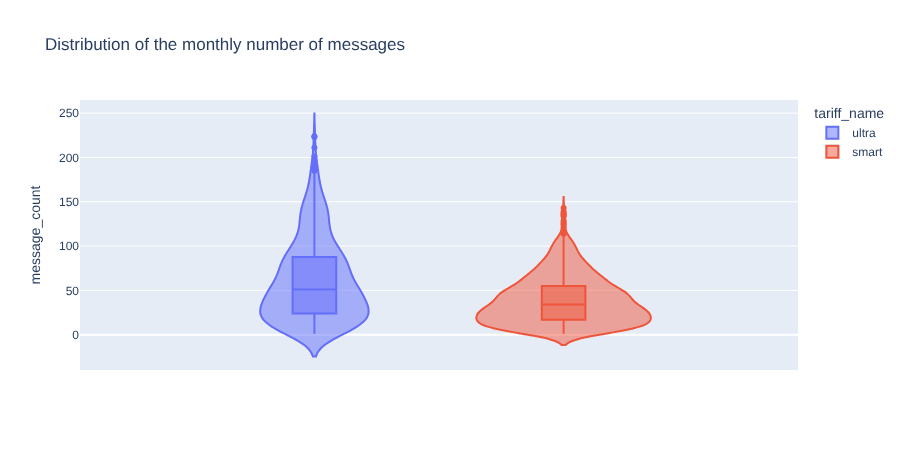

In [43]:
# plot the distribution of the monthly number of messages.
px.violin(earnings.loc[earnings['message_count']>=0], y="message_count", color='tariff_name', 
          box=True, title = 'Distribution of the monthly number of messages')

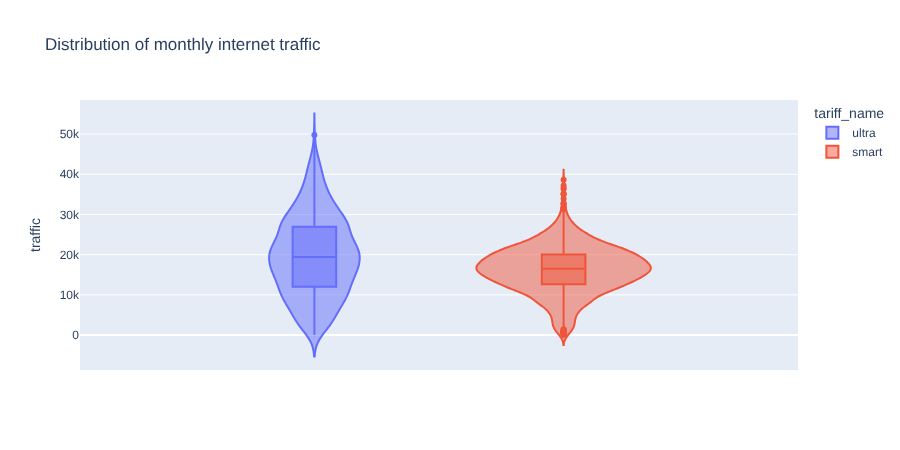

In [44]:
# plot the distribution of monthly internet traffic.
px.violin(earnings.loc[earnings['traffic']>=0], y="traffic", color='tariff_name', 
          box=True, title = 'Distribution of monthly internet traffic')

Outlier boundaries for the **ultra** plan:
- Call duration: **call_duration = 1609 (min)**
- Number of messages: **message_count = 185**
- Internet traffic: **traffic = 49789 (MB)**

Outlier boundaries for the **smart** plan:
- Call duration: **call_duration = 954 (min)**
- Number of messages: **message_count = 114**
- Internet traffic: **traffic: left = 1459; right = 31278 (MB)**

Now calculate the share of outliers in the data.

In [45]:
def print_outliers_rate(column, tariff, value_left=-999, value_right=10**9):
    """
    input: column (object) - analyzed parameter of the earnings table
           value_left (int64) - left outlier boundary
           value_right (int64) - right outlier boundary
           tariff (object) - plan name
    output: None
    description: the function counts the outliers and the total number of values (without missing ones) for the given plan,
                 and prints the share of outliers for this parameter in percent.
    """
    earnings_tariff = earnings.loc[earnings['tariff_name'] == tariff]
    num_outliers = len(earnings_tariff.loc[(earnings_tariff[column] >= value_right) |
                                           (earnings_tariff[column] <= value_left)]) 
    
    num_vals = sum(earnings_tariff[column] >= 0)
    rate = round(num_outliers / num_vals * 100, 2)
    print('Share of outliers for', column, ':', rate, '% of all data for the plan', tariff)

In [46]:
# calculate the shares of outliers for the ultra plan
print_outliers_rate('call_duration', 'ultra', value_right=1609)
print_outliers_rate('message_count', 'ultra', value_right=185)
print_outliers_rate('traffic', 'ultra', value_right=49789)

Share of outliers for call_duration : 0.21 % of all data for the plan ultra
Share of outliers for message_count : 1.26 % of all data for the plan ultra
Share of outliers for traffic : 0.1 % of all data for the plan ultra


In [47]:
# calculate the shares of outliers for the smart plan
print_outliers_rate('call_duration', 'smart', value_right=954)
print_outliers_rate('message_count', 'smart', value_right=114)
print_outliers_rate('traffic', 'smart', value_left=1459, value_right=31278)

Share of outliers for call_duration : 0.45 % of all data for the plan smart
Share of outliers for message_count : 0.73 % of all data for the plan smart
Share of outliers for traffic : 1.66 % of all data for the plan smart


There are few outliers in each parameter, so they can be removed without damaging the distributions much.
Remove all rows with outliers from the `earnings` table.

In [48]:
def erase_outliers(column, tariff, value_left=-999, value_right=10**9):
    """
    input: column (object) - analyzed parameter of the earnings table
           value_left (int64) - left outlier boundary
           value_right (int64) - right outlier boundary
           tariff (object) - plan name
    output: None
    description: the function removes the outliers of the parameter column for the given plan from the earnings table.
    """
    earnings.drop(earnings.loc[(earnings['tariff_name'] == tariff) &
                            ((earnings[column] >= value_right) |
                            (earnings[column] <= value_left))].index,
                  inplace=True
                 )

In [49]:
# save the number of records before removing the outliers in the variable num_rows_before
num_rows_before = len(earnings)

# remove the rows with outliers for the ultra plan
erase_outliers('call_duration', 'ultra', value_right=1609)
erase_outliers('message_count', 'ultra', value_right=185)
erase_outliers('traffic', 'ultra', value_right=49789)

# remove the rows with outliers for the smart plan
erase_outliers('call_duration', 'smart', value_right=954)
erase_outliers('message_count', 'smart', value_right=114)
erase_outliers('traffic', 'smart', value_left=1459, value_right=31278)

# calculate the share of removed outliers:
print('Share of removed outliers:', round((num_rows_before - len(earnings)) / num_rows_before * 100, 2), '%')

Share of removed outliers: 2.24 %


### Conclusions

- The data types are converted successfully. Unnecessary columns are removed.
- The number of calls, messages and internet sessions grows linearly over the year. This may be due to the growing popularity of the operator.
- Some calls have zero duration and some internet sessions have zero traffic. This may be due to cancelled calls or sessions. The zero values are left as they are. The distributions of the other values in these columns resemble a Poisson distribution. No anomalous values were found. The data is slightly right-skewed.
- For each customer the following are calculated by month: number of calls, minutes used, messages sent, internet traffic used, and monthly revenue. The results are stored in pivot tables.
- The calculated parameters are checked for outliers. The share of outliers is at most 1.66% of the data for any single parameter, and 2.24% in total. The rows with outliers are removed and are not used in further analysis.

## Step 3. Data Analysis

### 3.1 Call Minutes

Look in more detail at the number of call minutes per month needed by users of different plans.
Calculate the mean, variance and standard deviation.
We want to estimate the needs of the users. To reduce the influence of random outliers, first calculate the average monthly value for each user and then calculate the statistics.
For the statistics, create the function `calc_stats()`.

In [50]:
def calc_stats(column, tariff):
    """
    input:   column - parameter of the earnings table to calculate the statistics for
             tariff - plan whose users are analyzed
    output:  stat_tariff - slice of the data for the plan with the average monthly values of 'column'
    description:  - The function selects the data 'column' from the 'earnings' table for the plan 'tariff',
                  - calculates the average monthly values for the users
                  - prints the statistics of the slice (mean, median, variance, standard deviation)
    """
    # select the data 'column' of the 'earnings' table for the users of the plan 'tariff'
    # then group by user and find the average of 'column' over all months of use
    stat_tariff = (earnings
                     .loc[(earnings['tariff_name'] == tariff) & (earnings[column] >= 0)]
                     .groupby('user_id')[column]
                     .agg('mean')
                    )
    print('Plan "' + tariff + '":')
    # calculate the mean with mean()
    print('Mean:', round(stat_tariff.mean(), 0))
    print('Median:', round(stat_tariff.median(), 0))
    # calculate the variance with np.var()
    print('Variance:', round(np.var(stat_tariff), 0))
    # calculate the standard deviation as the square root of the variance, np.sqrt(np.var())
    print('Standard deviation:', round(np.sqrt(np.var(stat_tariff)), 0))
    return stat_tariff

In [51]:
minutes_smart = calc_stats('call_duration', 'smart')

Plan "smart":
Mean: 416.0
Median: 428.0
Variance: 21865.0
Standard deviation: 148.0


In [52]:
minutes_ultra = calc_stats('call_duration', 'ultra')

Plan "ultra":
Mean: 540.0
Median: 519.0
Variance: 70369.0
Standard deviation: 265.0


- Plot the histograms for both plans in one set of axes. For convenience, create the function `show_histograms()`.

In [53]:
def show_histograms(data_smart, data_ultra, ax_name, bins, lims):
    """
    input: data_smart (float64) - slice of the data for the smart plan with the average monthly values of the analyzed parameter
           data_ultra (float64) - slice of the data for the ultra plan with the average monthly values of the analyzed parameter
           ax_name (str) - description of the analyzed parameter
           bins (int)   - number of histogram bins
           lims (tuple) - range of the values used for the histograms
    output: None
    The function draws two histograms of the analyzed parameter in one set of axes.
    The histograms show the density of the values for clarity.
    """
    ax = (data_smart
          .plot(kind = 'hist',
                histtype = 'step',       # this type is convenient for comparing two histograms
                bins = bins,
                range = lims,
                alpha = 0.5,
                linewidth = 2,           # line width
                grid = True,
                density = True,          # show the density of the data
                legend = True,           # show the legend
                title = 'Density',
                label = 'smart'  # label for the legend
               )
         )
    (data_ultra
     .plot(kind = 'hist',
           histtype = 'step',
           ax = ax,               # draw in the axes of the previous histogram
           bins = bins,
           range = lims,
           alpha = 0.5,
           linewidth = 2,
           grid = True,
           density = True,
           legend = True,
           label = ' ultra'
          )
    )
    # density=True is needed to show two histograms in one set of axes.
    ax.set_title(ax_name + '. Density', fontsize=15)
    ax.set_xlabel(ax_name + '. Average monthly value', fontsize=12)
    ax.set_ylabel('density', fontsize=14)
    plt.show()

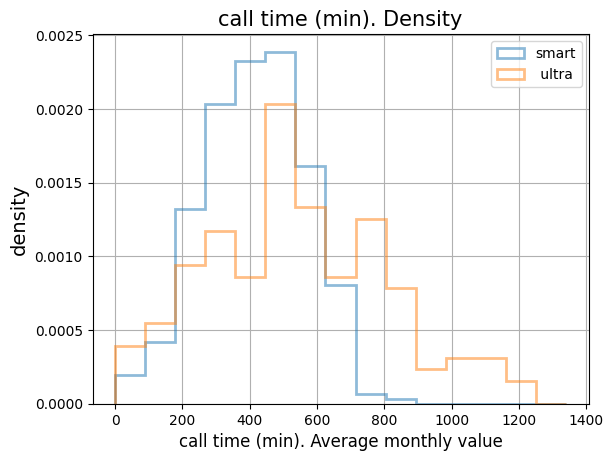

In [54]:
show_histograms(minutes_smart, minutes_ultra, 'call time (min)', bins=15, lims=(0,1340))

- Find the percentage of users who exceed the number of minutes included in the monthly fee.
For this, use `st.percentileofscore()`, which returns the percentile rank of a value.

In [55]:
print('Share of smart users who exceed the number of minutes included in the plan:',
      round(100 - st.percentileofscore(minutes_smart, 500), 1), '%')
print('Share of ultra users who exceed the number of minutes included in the plan:',
      round(100 - st.percentileofscore(minutes_ultra, 3000), 1), '%')

Share of smart users who exceed the number of minutes included in the plan: 29.4 %
Share of ultra users who exceed the number of minutes included in the plan: 0.0 %


- The mean and median are close for both plans, so the skew is minimal.
- The mean of the smart plan is smaller than that of the ultra plan (416 and 540 minutes). The standard deviations also show that the smart values are more concentrated around their mean (the spread of the ultra plan is larger).
- On the histograms the ultra data is also shifted to the right (towards more minutes) compared to the smart data. The histograms are close to a normal distribution. The individual peaks are explained by the small amount of data (only 500 users across 2 plans).
- By the three-sigma rule, 99.7% of the values lie in:
    - **(0, 860)** minutes for the smart plan
    - **(0, 1335)** minutes for the ultra plan
    - The other values can be considered outliers.
- On average **29.4%** of the **smart** users exceed the minute limit and pay for an extra package. It may be worth optimizing the plan or offering them a new one.
- The **ultra** users on average do not exceed the minute limit and do not pay extra.

### 3.2 Number of Messages

Look in more detail at the number of messages per month needed by users of different plans.
Calculate the mean, variance and standard deviation.
We want to estimate the needs of the users. To reduce the influence of random outliers, first calculate the average monthly value for each user and then calculate the statistics.

In [56]:
messages_smart = calc_stats('message_count', 'smart')

Plan "smart":
Mean: 37.0
Median: 33.0
Variance: 611.0
Standard deviation: 25.0


In [57]:
messages_ultra = calc_stats('message_count', 'ultra')

Plan "ultra":
Mean: 63.0
Median: 58.0
Variance: 1674.0
Standard deviation: 41.0


- Plot the histograms for both plans in one set of axes.

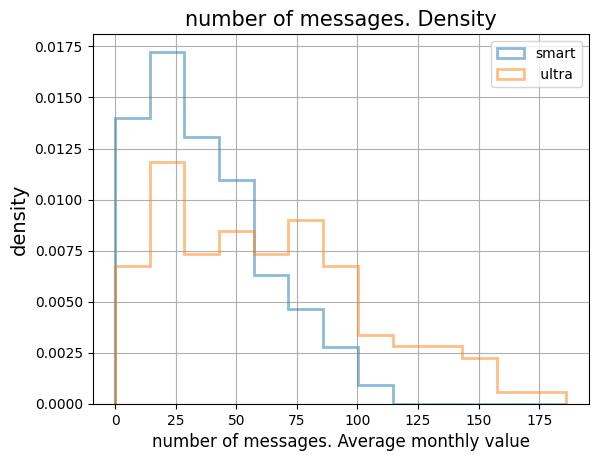

In [58]:
show_histograms(messages_smart, messages_ultra, 'number of messages', bins=13, lims=(0,186))

- Find the percentage of users who exceed the number of messages included in the monthly fee.

In [59]:
print('Share of smart users who exceed the number of messages included in the plan:',
      round(100 - st.percentileofscore(messages_smart, 50), 1), '%')
print('Share of ultra users who exceed the number of messages included in the plan:',
      round(100 - st.percentileofscore(messages_smart, 1000), 1), '%')

Share of smart users who exceed the number of messages included in the plan: 26.0 %
Share of ultra users who exceed the number of messages included in the plan: 0.0 %


- The mean and median are close for both plans, with a slight right skew.
- The mean of the smart plan is smaller than that of the ultra plan (37 and 63 messages). The standard deviations (25 and 41) also show that the smart values are more concentrated around their mean (the spread of the ultra plan is larger).
- On the histograms the ultra data is also shifted to the right (towards more messages) compared to the smart data. The histograms resemble a Poisson distribution. The individual peaks are explained by the small amount of data (only 500 users across 2 plans).
- Many users send few messages, which explains the cluster of values near 0. It may be worth considering a new plan with a minimal message allowance.
- By the three-sigma rule, 99.7% of the values lie in:
    - **(0, 112)** messages for the smart plan
    - **(0, 186)** messages for the ultra plan
    - The other values can be considered outliers.
- On average **26.0%** of the **smart** users exceed the message limit and pay for an extra package. It may be worth optimizing the plan or offering them a new one.

### 3.3 Internet Traffic

Look in more detail at the amount of internet traffic per month needed by users of different plans.
Calculate the mean, variance and standard deviation.
We want to estimate the needs of the users. To reduce the influence of random outliers, first calculate the average monthly value for each user and then calculate the statistics.

In [60]:
traffic_smart = calc_stats('traffic', 'smart')

Plan "smart":
Mean: 16005.0
Median: 16157.0
Variance: 15536814.0
Standard deviation: 3942.0


In [61]:
traffic_ultra = calc_stats('traffic', 'ultra')

Plan "ultra":
Mean: 19565.0
Median: 18730.0
Variance: 64815582.0
Standard deviation: 8051.0


- Plot the histograms for both plans in one set of axes.

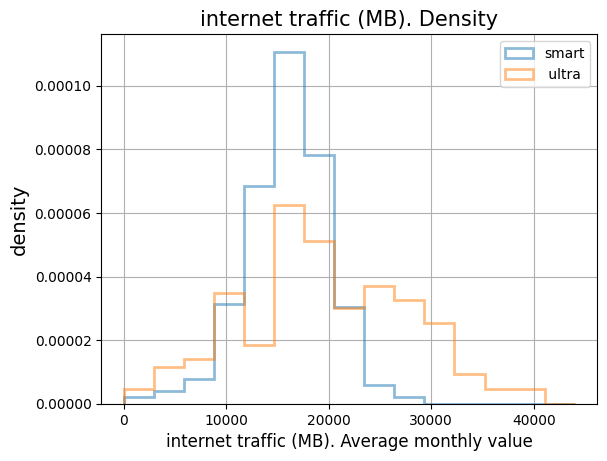

In [62]:
show_histograms(traffic_smart, traffic_ultra, 'internet traffic (MB)', bins=15, lims=(0,44000))

- Find the percentage of users who exceed the number of megabytes included in the monthly fee.

In [63]:
print('Share of smart users who exceed the number of megabytes included in the plan:',
      round(100 - st.percentileofscore(traffic_smart, 15360), 1), '%')
print('Share of ultra users who exceed the number of megabytes included in the plan:',
      round(100 - st.percentileofscore(traffic_ultra, 30720), 1), '%')

Share of smart users who exceed the number of megabytes included in the plan: 60.6 %
Share of ultra users who exceed the number of megabytes included in the plan: 10.2 %


- The mean and median are close for both plans; the remaining skew can be explained by the small amount of data (only 500 users across 2 plans).
- The mean of the smart plan is smaller than that of the ultra plan (16005 and 19565 megabytes). The standard deviations also show that the smart values are more concentrated around their mean (the spread of the ultra plan is larger).
- On the histograms the ultra data is also shifted to the right (towards more traffic) compared to the smart data. The histograms are close to a normal distribution. The individual peaks are explained by the small amount of data.
- By the three-sigma rule, 99.7% of the values lie in:
    - **(0, 27831)** megabytes for the smart plan
    - **(0, 43718)** megabytes for the ultra plan
    - The other values can be considered outliers.
- On average **60.6%** of the **smart** users exceed the traffic limit and pay for an extra package. It may be worth optimizing the plan or offering these users a new one.
- On average **10.2%** of the **ultra** users exceed the traffic limit and pay for an extra package. This is also a significant share, so the plan conditions may need to be reworked.

### 3.4 Revenue by Plan

**Plan** for analyzing the monthly revenue by plan:
**1)** Plot histograms of the average monthly revenue per user for the different plans.
**2)** Look at the average revenue per user by month.
**3)** Determine the share of revenue that comes from overage payments for each plan.
**4)** Determine how much revenue there is per customer.
**5)** Pick the most promising plan to promote.

Text(0, 0.5, 'number of users')

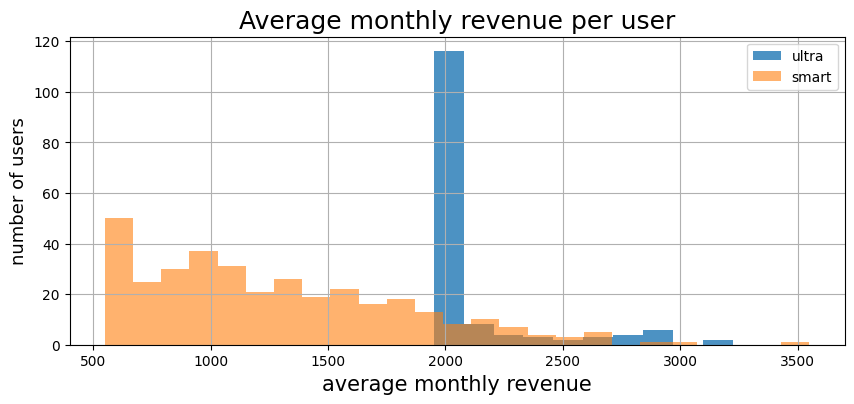

In [64]:
fig, axes = plt.subplots(figsize=(10,4))   # create the axes for the histograms
# plot the histograms of the average monthly revenue per user for the different plans in axes
(earnings
 .loc[earnings['tariff_name'] == 'ultra']   # slice of the data for the ultra plan
 .groupby('user_id')['earning']             # group the data by user
 .agg('mean')                               # calculate the average monthly revenue of each user
 .hist(bins=10, ax = axes, alpha=0.8)       # axes - axes of the plot
)
(earnings
 .loc[earnings['tariff_name'] == 'smart']   # slice of the data for the smart plan
 .groupby('user_id')['earning']
 .agg('mean')
 .hist(bins=25, ax = axes, alpha=0.6)               
)
axes.legend(('ultra', 'smart'))
axes.set_title('Average monthly revenue per user', fontsize=18)
axes.set_xlabel('average monthly revenue', fontsize=15)
axes.set_ylabel('number of users', fontsize=13)

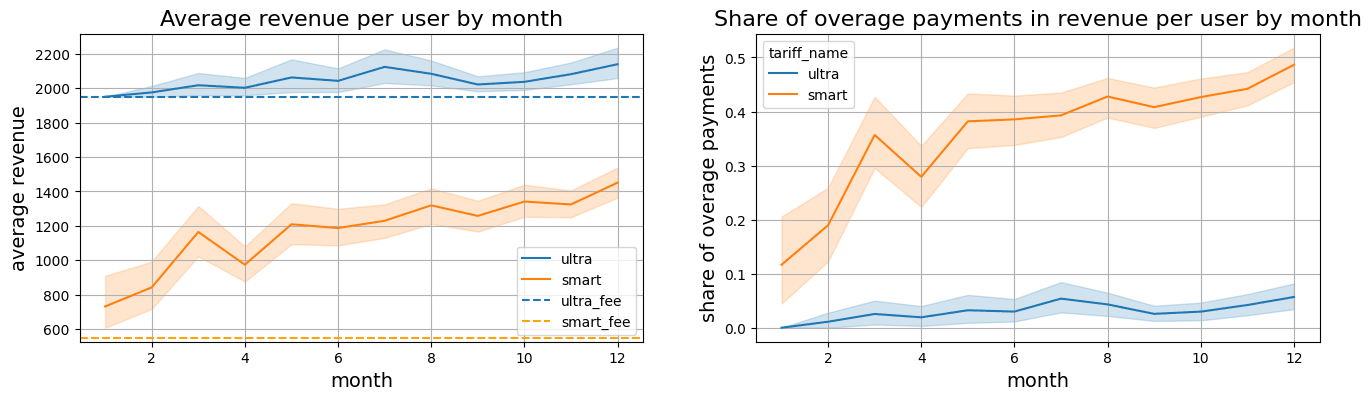

In [65]:
fig, axes = plt.subplots(nrows=1,ncols=2,figsize=(16,4))   # create the axes for two side-by-side plots

# in axes[0] (left) plot the average revenue per user by month
lines = sns.lineplot(x='month', 
                     y='earning', 
                     data=earnings, 
                     hue='tariff_name',
                     estimator='mean',
                     ax=axes[0])
# draw the monthly fee of each plan as a horizontal line
lines.axhline(1950, ls='--', label='ultra_fee')
lines.axhline(550, ls='--', color='orange', label='smart_fee')
axes[0].set_title('Average revenue per user by month', fontsize=16)
axes[0].set_xlabel('month', fontsize=14)
axes[0].set_ylabel('average revenue', fontsize=14)
axes[0].grid()
axes[0].legend()

# in axes[1] (right) plot the share of overage payments in the average revenue per user by month
sns.lineplot(x='month', 
             y=(earnings['earning']-earnings['rub_monthly_fee'])/earnings['earning'], 
             data=earnings, 
             hue='tariff_name',
             estimator='mean',
             ax = axes[1])
axes[1].set_title('Share of overage payments in revenue per user by month', fontsize=16)
axes[1].set_xlabel('month', fontsize=14)
axes[1].set_ylabel('share of overage payments', fontsize=14)
plt.grid()

- The smart plan has a relatively small monthly fee, but its package does not cover the users' needs, so customers pay for extra services (up to 50% of their payment on average). Changing the plan conditions or offering these customers another plan should be considered.
- The ultra plan has a relatively high monthly fee, but its package is enough for almost all users (overage share does not exceed 5%). On average no more than 10% of users buy extra internet traffic in a given month. Such customers could be offered alternative traffic conditions.
- However, the plots show that with all overage payments included, smart users on average pay less per month than ultra users.
- Almost nobody on the ultra plan buys extra call minutes or messages. A smaller package of these services with a lower monthly fee should be considered.
- Overall the **ultra** plan looks like the better one to promote.

### Conclusions

- The statistics (call minutes, messages, internet traffic) of the ultra and smart users are analyzed. Means, variances and standard deviations are calculated.
- For all analyzed parameters, the values of the ultra users are higher than those of the smart users.
- The boundaries of random outliers are determined by the three-sigma rule.
- The average percentages of users who exceed the plan limits are also determined for each parameter. A large share of the smart users pay extra for additional services in all analyzed metrics. Changing the plan conditions or offering these users new plans could help avoid customer churn.
- The revenue histograms also show that most smart users do not fit into the package limits and therefore pay a lot extra. Among the ultra users there is no such tendency: most of them pay only the monthly fee.
- The average revenue per smart user grows over time. Over the year, the overage share of the average revenue per user grew **from 10% to 50%**. This may lead to negative customer feedback.
The ultra plan shows this tendency to a much smaller extent (overage share of about **5%**).
The **ultra** plan looks like the better one to promote.

## Step 4. Hypothesis Testing

### 4.1 Average Revenue of "Ultra" and "Smart" Users

- Test the hypothesis:
    - "The average revenue of users of the Ultra and Smart plans differs"
- First, state the null hypothesis H0:
    - "The average revenue of Ultra users equals the average revenue of Smart users"
- State the alternative hypothesis H1:
    - "The average revenue of Ultra users does not equal the average revenue of Smart users"
- Set the significance level `alpha = 0.05`
- The samples of Ultra and Smart customers are independent. To calculate the test statistic and the `p-value`, use `st.ttest_ind`.

In [66]:
earning_smart = (earnings
                .loc[earnings['tariff_name'] == 'smart']   # slice of the data for the smart plan
                .groupby('user_id')['earning']             # group the data by user
                .agg('mean')                               # calculate the average monthly revenue of each user
                )
earning_ultra = (earnings
                .loc[earnings['tariff_name'] == 'ultra']   # slice of the data for the ultra plan
                .groupby('user_id')['earning']             # group the data by user
                .agg('mean')                               # calculate the average monthly revenue of each user
                )
results = st.ttest_ind(earning_smart, earning_ultra, equal_var=False) # assume the sample variances are different
print('p-value:', results.pvalue)

p-value: 2.2513444249137395e-71


- The `p-value` is practically 0 (much smaller than `alpha`), so the null hypothesis H0 is very unlikely. The empirical data allow us to reject the null hypothesis in favor of the alternative H1:
- "The average revenue of Ultra users does not equal the average revenue of Smart users"

### 4.2 Average Revenue of Users from Moscow and from Other Regions

- Test the hypothesis:
    - "The average revenue of users from Moscow differs from the revenue of users from other regions"
- First, state the null hypothesis H0:
    - "The average revenue of users from Moscow equals the average revenue of users from other regions"
- State the alternative hypothesis H1:
    - "The average revenue of users from Moscow does not equal the average revenue of users from other regions"
- Set the significance level `alpha = 0.05`
- The samples of customers from Moscow and from other regions are independent. To calculate the test statistic and the `p-value`, use `st.ttest_ind`.

In [67]:
earning_moscow = (earnings
                .query('city == "Москва"')                 # slice of the data for Moscow (the city name is a value in the dataset)
                .groupby('user_id')['earning']             # group the data by user
                .agg('mean')                               # calculate the average monthly revenue of each user
                )
earning_other = (earnings
                .query('city != "Москва"')                 # slice of the data for all cities except Moscow
                .groupby('user_id')['earning']             # group the data by user
                .agg('mean')                               # calculate the average monthly revenue of each user
                )
results = st.ttest_ind(earning_moscow, earning_other, equal_var=False) # assume the sample variances are different
print('p-value:', results.pvalue)

p-value: 0.46622604870106665


- The `p-value` is **0.47** > `alpha`, so there is no reason to reject the null hypothesis. The empirical data do not contradict H0:
- "The average revenue of users from Moscow equals the average revenue of users from other regions"

### 4.3 Alternative Hypothesis Tests

- To use Student's t-test, the data must meet the following requirements:
    - The data must be normally distributed, but only for a small number of observations (n < 30). For larger samples the distribution of the sample mean is asymptotically normal.
    - When the two-sample test for independent samples is used with equal variances, the variances must be equal (homogeneity).
- Check the sample distributions from the previous sections against these conditions and, if needed, use alternative tests.

**1)** Alternative test of the average revenue of "Ultra" and "Smart" users

- Check the normality of the samples `earning_smart` and `earning_ultra`.

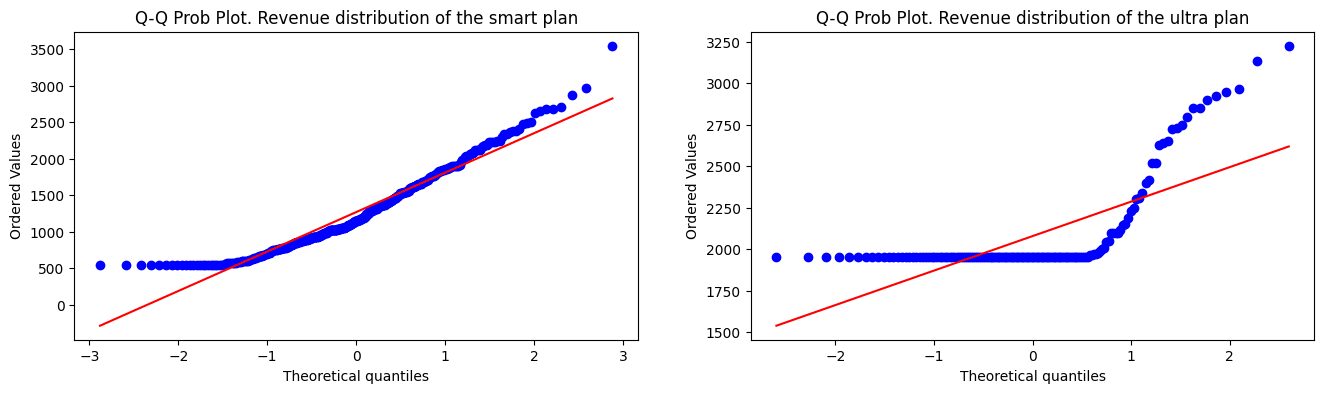

In [68]:
plt.figure(figsize=(16,4))
ax1 = plt.subplot(121)
# plot quantile-quantile plots with probplot() from the stats library for both samples
st.probplot(earning_smart, dist="norm", plot=plt)
ax1.set_title('Q-Q Prob Plot. Revenue distribution of the smart plan')
ax2 = plt.subplot(122)
st.probplot(earning_ultra, dist="norm", plot=plt)
ax2.set_title('Q-Q Prob Plot. Revenue distribution of the ultra plan')
plt.show()

- The revenue distribution of the smart plan is close to normal. The revenue distribution of the ultra plan is far from normal.
- So Student's t-test used in Section 4.1 does not give optimal results here. Try the **Mann-Whitney** test instead.
- Set the significance level **alpha** to **0.05**.

In [69]:
# compare the samples with the Mann-Whitney test
stat, p = st.mannwhitneyu(earning_smart, earning_ultra)
print('Statistics = {:.3f}, p-value = {:.3f}'.format(stat, p))
# interpretation
alpha = 0.05
if p > alpha:
    print('p-value is greater than alpha = 0.05. No reason to reject the null hypothesis H0')
else:
    print('p-value is less than alpha = 0.05. There is reason to reject the null hypothesis in favor of the alternative H1')

Statistics = 5267.500, p-value = 0.000
p-value is less than alpha = 0.05. There is reason to reject the null hypothesis in favor of the alternative H1


- The Mann-Whitney test gives the same result as the earlier Student's t-test.
- "The average revenue of Ultra users does not equal the average revenue of Smart users"

**2)** Alternative test of the average revenue of users from Moscow and from other regions.

- Check the normality of the samples `earning_moscow` and `earning_other`.

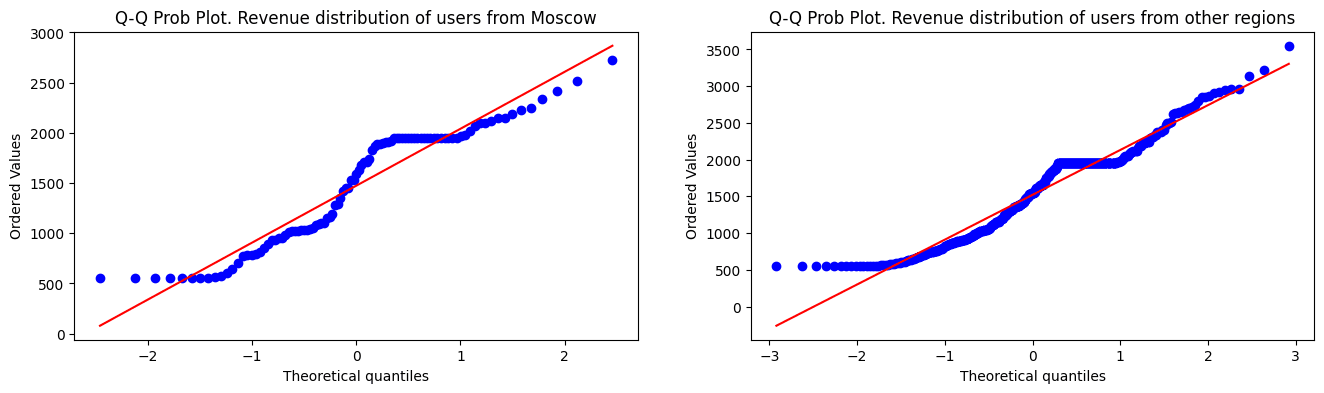

In [70]:
plt.figure(figsize=(16,4))
ax1 = plt.subplot(121)
# plot quantile-quantile plots with probplot() from the stats library for both samples
st.probplot(earning_moscow, dist="norm", plot=plt)
ax1.set_title('Q-Q Prob Plot. Revenue distribution of users from Moscow')
ax2 = plt.subplot(122)
st.probplot(earning_other, dist="norm", plot=plt)
ax2.set_title('Q-Q Prob Plot. Revenue distribution of users from other regions')
plt.show()

- The plots show that the sample distributions differ slightly from normal.
- Additionally check the equality of the sample variances with Levene's test.

- The null and alternative hypotheses of Levene's test:
**H0**: All k sample populations have equal variances.
**H1**: At least one of the k sample populations has a variance different from the others.
Set the significance level **alpha** to **0.05**.

In [71]:
# use levene() from the stats library
stat, p = st.levene(earning_moscow, earning_other)
print('Statistics = {:.3f}, p-value = {:.3f}'.format(stat, p))

Statistics = 0.110, p-value = 0.740


- The p-value is larger than alpha, so there is no reason to believe that the variances of `earning_moscow` and `earning_other` differ.
- Since the sample distributions differ slightly from normal, use the **Mann-Whitney** test for the hypothesis:
    - "The average revenue of users from Moscow differs from the revenue of users from other regions"
- Set the significance level **alpha** to **0.05**.

In [72]:
# compare the samples with the Mann-Whitney test
stat, p = st.mannwhitneyu(earning_moscow, earning_other)
print('Statistics = {:.3f}, p-value = {:.3f}'.format(stat, p))
# interpretation
alpha = 0.05
if p > alpha:
    print('p-value is greater than alpha = 0.05. No reason to reject the null hypothesis H0')
else:
    print('p-value is less than alpha = 0.05. There is reason to reject the null hypothesis in favor of the alternative H1')

Statistics = 19057.500, p-value = 0.640
p-value is greater than alpha = 0.05. No reason to reject the null hypothesis H0


- The Mann-Whitney test gives the same result as the earlier Student's t-test.
- "The average revenue of users from Moscow does not differ from the average revenue of users from other regions"

### Conclusions

- First hypothesis:
The empirical data allow us to reject the null hypothesis in favor of the alternative H1:
    - "The average revenue of Ultra users does not equal the average revenue of Smart users"
- Second hypothesis:
The empirical data do not contradict H0:
    - "The average revenue of users from Moscow equals the average revenue of users from other regions"

## Step 5. Overall Conclusion

**1)** The data on a sample of customers of the operator is loaded and analyzed. The data types are converted according to the project description. Zero values of call duration and internet sessions are analyzed and left as they are. Missing values are also studied and left as they are.
**2)** For each customer the following are calculated by month: number of calls, minutes used, messages sent, internet traffic used, and monthly revenue. The results are stored in pivot tables.
Outliers in the analyzed parameters were also found and removed (about 2.2% of the data).
**3)** The statistics (call minutes, messages, internet traffic) of the ultra and smart users are analyzed. Means, variances and standard deviations are calculated. The boundaries of random outliers are determined by the three-sigma rule.
**4)** Most smart users do not fit into the package limits and therefore pay a lot extra. Better conditions should be designed for these users to avoid possible churn. Among the ultra users there is no such tendency: most of them pay only the monthly fee.
**5)** The average revenue per smart user grows over time. Over the year, the overage share of the average revenue per user grew **from 10% to 50%**. This may lead to negative customer feedback.
The ultra plan shows this tendency to a much smaller extent (overage share of about **5%**). Ways to optimize the ultra plan are suggested.
- The **ultra** plan looks like the better one to promote.

**6)** Hypotheses are tested with Student's t-test, with the following conclusions:
   - The empirical data allow us to reject the null hypothesis in favor of the alternative H1:
   **"The average revenue of Ultra users does not equal the average revenue of Smart users"**
   - The empirical data do not contradict H0:
   **"The average revenue of users from Moscow equals the average revenue of users from other regions"**

- The samples were also checked against the conditions for applying Student's t-test.
Alternative hypothesis tests with the Mann-Whitney test were run to confirm the earlier results.